# 01. Data and labels

**Question of the project:** which Medicare Part D prescribers should an auditor look at first?

This notebook loads the two public datasets, explains what is in them, and builds the labels the models will learn from. The most important decision here is how to define a positive without leaking information from the future.

## The two datasets

**CMS Medicare Part D Prescribers by Provider.** Medicare Part D is the prescription drug benefit of Medicare. CMS publishes one row per prescriber per year with everything that prescriber wrote for Medicare patients that year, aggregated: number of prescriptions (claims), days of supply, cost, brand vs generic, opioids, antibiotics, antipsychotics for patients 65+, and a profile of the prescriber's patients (age, sex, low-income subsidy, dual Medicare/Medicaid eligibility, average risk score). There is no patient-level data, and CMS suppresses counts below 11 for privacy. Files are released about 18 months after the end of the year.

**HHS OIG List of Excluded Individuals/Entities (LEIE).** The Office of Inspector General (OIG) excludes individuals and companies from federal health programs; an excluded provider cannot be paid by Medicare or Medicaid. Each record has the exclusion type (the section of the law that applies) and the exclusion date. The file contains only exclusions currently in effect: people who were later reinstated are removed.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from src.data import (load_partd, load_leie, build_labels, summarize_labels, save_processed,
                      EXCLUSION_TYPE_NAMES, FRAUD_TYPES)

pd.set_option("display.max_columns", 50)
YEARS = (2022, 2023, 2024)

## Load Part D

We keep only the columns we need for modeling and drop names and street addresses: the model should learn from how someone prescribes, not from who they are.

In [2]:
partd = {y: load_partd(y) for y in YEARS}
pd.DataFrame({y: {"prescribers": len(df), "unique NPIs": df["Prscrbr_NPI"].nunique(),
                  "total claims (M)": round(df["Tot_Clms"].sum() / 1e6, 1),
                  "total drug cost ($B)": round(df["Tot_Drug_Cst"].sum() / 1e9, 1)}
              for y, df in partd.items()})

,2022,2023,2024
prescribers,1332309.0,1380665.0,1416883.0
unique NPIs,1332309.0,1380665.0,1416883.0
total claims (M),1542.6,1615.7,1709.8
total drug cost ($B),240.2,275.6,288.4


In [3]:
partd[2022].describe(percentiles=[.5, .99]).T.round(1).head(20)

,count,mean,std,min,50%,99%,max
Tot_Clms,1332309.0,1157.9,2777.3,11.0,199.0,12377.0,281716.0
Tot_30day_Fills,1332309.0,2105.3,4964.3,11.0,254.0,24170.9,282922.6
Tot_Drug_Cst,1332309.0,180303.9,531373.4,0.0,11517.0,2352844.4,48734106.5
Tot_Day_Suply,1332309.0,59056.3,141076.6,11.0,5048.0,695443.3,6414770.0
Tot_Benes,1189133.0,168.7,392.6,11.0,87.0,947.0,204782.0
Brnd_Tot_Clms,722094.0,269.9,799.3,0.0,55.0,2388.1,279934.0
Brnd_Tot_Drug_Cst,722094.0,217104.2,539651.4,0.0,33552.3,2370966.4,48626789.7
Gnrc_Tot_Clms,1293817.0,1004.8,2382.0,0.0,180.0,10806.8,232192.0
Gnrc_Tot_Drug_Cst,1293817.0,28524.9,73339.9,0.0,3632.1,296232.8,12896464.2
MAPD_Tot_Clms,1101860.0,740.5,1788.1,0.0,142.0,8101.0,158690.0


**Suppressed values.** Empty cells are values CMS hid because the count was below 11 (or the category does not apply). We keep them as missing rather than zero: "fewer than 11 opioid claims" is not the same as "no opioid claims", and tree models can learn from the pattern of missingness.

In [4]:
(partd[2022].isna().mean().sort_values(ascending=False).head(12) * 100).round(1).rename("% missing")

Brnd_Tot_Clms             45.8
Brnd_Tot_Drug_Cst         45.8
Bene_Ndual_Cnt            41.0
Bene_Dual_Cnt             41.0
Opioid_Tot_Benes          39.4
Antpsyct_GE65_Tot_Clms    37.6
Opioid_LA_Tot_Clms        32.3
Opioid_LA_Tot_Suply       32.3
Antbtc_Tot_Clms           29.2
Bene_Feml_Cnt             28.1
Opioid_Tot_Drug_Cst       25.9
Opioid_Tot_Suply          25.9
Name: % missing, dtype: float64

## Load the LEIE

Only about one in ten LEIE records has an NPI (the national provider identifier), so those are the only ones we can link to Part D. Many records without NPI are older exclusions or businesses.

LEIE records: 84,224; with NPI and a valid date: 8,844


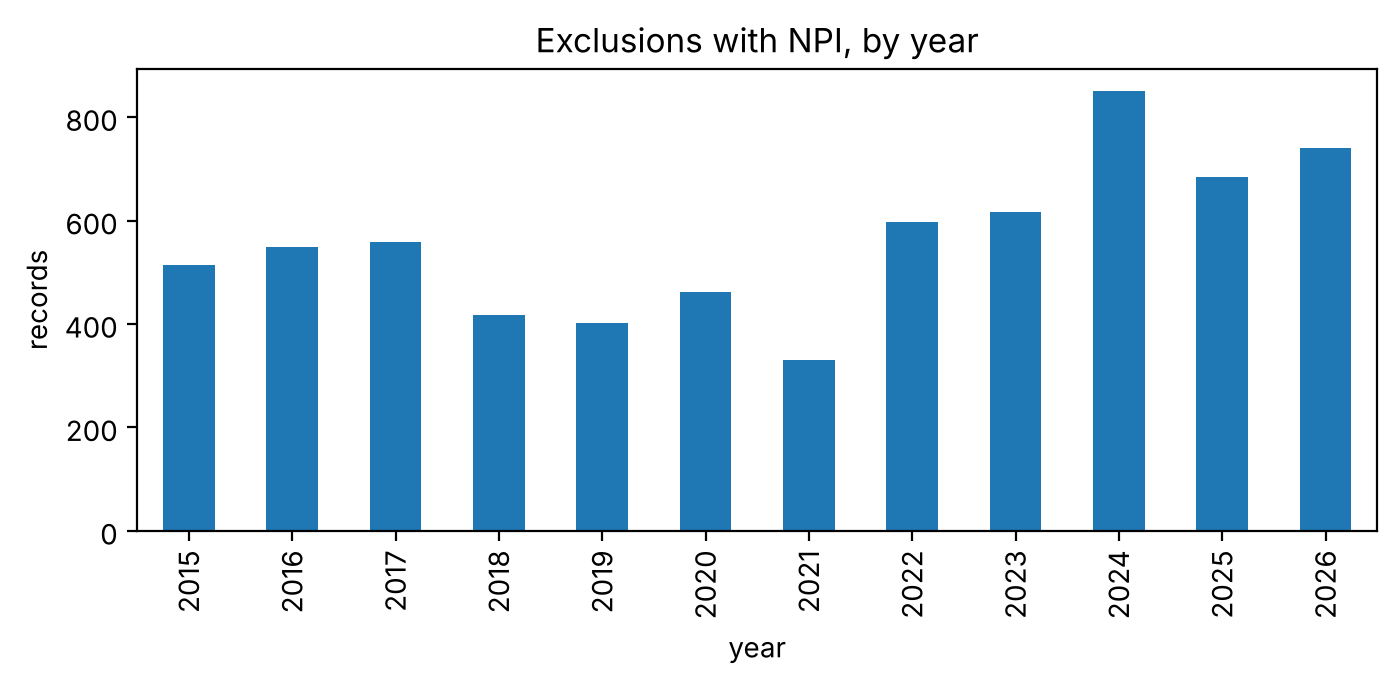

In [5]:
leie_all = pd.read_csv(sorted(Path("../data/raw").glob("LEIE_*.csv"))[-1], dtype=str)
leie = load_leie()
print(f"LEIE records: {len(leie_all):,}; with NPI and a valid date: {len(leie):,}")
leie["excl_date"].dt.year.value_counts().sort_index().loc[2015:].plot.bar(
    title="Exclusions with NPI, by year", xlabel="year", ylabel="records", figsize=(8, 3));

## How many prescribers were excluded, and when?

Joining by NPI, we can see for each Part D year how many prescribers were excluded before, during, or after that year. Those excluded **before** the year are rare (excluded providers stop being paid), which is a good sanity check.

In [6]:
rows = []
for y, df in partd.items():
    m = df.merge(leie, left_on="Prscrbr_NPI", right_on="NPI")
    yr = m["excl_date"].dt.year
    rows.append({"year": y, "matched": len(m), "excluded before": (yr < y).sum(),
                 "during": (yr == y).sum(), "after": (yr > y).sum()})
pd.DataFrame(rows).set_index("year")

,matched,excluded before,during,after
year,,,,
2022,754,2,55,697
2023,520,1,43,476
2024,323,1,54,268


## Defining a positive without leaking the future

Features describe prescribing in year *Y*. A prescriber is **positive** if the OIG excluded them in the **two years after** *Y* (for 2022: between Jan 2023 and Dec 2024). Prescribers excluded on or before Dec 31 of year *Y* are **dropped**: their exclusion was already known, so including them would let the model "see" the answer.

This mirrors how the model would be used: score this year's prescribers, and see who gets excluded next.

| Use | Features from | Positive if excluded in |
|---|---|---|
| Train | 2022 | 2023-2024 |
| Validation | 2023 | 2024-2025 |
| Test | 2024 | 2025-2026 (2026 is partial: file downloaded Nov 2026) |

Train and test labels do not overlap in time, so the test is a fair look at future performance.

## Two definitions of the label

Not every exclusion is about fraud in prescribing. We build two labels and will compare models on both:

- **`label_any`**: any exclusion in the window.
- **`label_fraud`**: only fraud-related types: 1128(a)(1) program-related crimes, 1128(a)(3) health care fraud felony, 1128(a)(4) controlled substance felony, 1128(b)(7) fraud and kickbacks.

The most common type overall, 1128(b)(4) license revocation or suspension, can follow fraud but also malpractice or impairment, so it is in `label_any` but not in `label_fraud`.

In [7]:
labeled = {y: build_labels(df, leie, y) for y, df in partd.items()}
pd.DataFrame({y: summarize_labels(df) for y, df in labeled.items()})

,2022,2023,2024
prescribers,1332252.00,1380621.00,1416828.00
positives_any,309.00,290.00,268.00
positives_fraud,185.00,146.00,113.00
rate_any_per_10k,2.32,2.10,1.89
rate_fraud_per_10k,1.39,1.06,0.80


In [8]:
pos = labeled[2022].query("label_any == 1")
types = (pos["excl_type"].str.strip().value_counts().rename("prescribers").to_frame()
         .assign(description=lambda t: t.index.map(EXCLUSION_TYPE_NAMES).fillna("other"),
                 in_fraud_label=lambda t: t.index.isin(FRAUD_TYPES)))
types

,prescribers,description,in_fraud_label
excl_type,,,
1128b4,107,License revocation or suspension,False
1128a1,105,Conviction: program-related crime,True
1128a4,49,Felony: controlled substances,True
1128a3,24,Felony: health care fraud,True
1128a2,10,Conviction: patient abuse or neglect,False
1128b7,7,"Fraud, kickbacks, prohibited acts",True
1128b1,4,Misdemeanor: health care fraud,False
1128b3,2,other,False
1128b6,1,other,False


## Who are the positives?

Specialty mix of positives versus everyone. If positives were concentrated in one specialty, a model could look good just by learning specialty; that is why later features compare each prescriber with peers of the same specialty.

In [9]:
d = labeled[2022]
spec = pd.DataFrame({
    "all prescribers (%)": d["Prscrbr_Type"].value_counts(normalize=True) * 100,
    "positives (%)": d.loc[d.label_any == 1, "Prscrbr_Type"].value_counts(normalize=True) * 100,
}).fillna(0).sort_values("positives (%)", ascending=False).head(12).round(2)
spec

,all prescribers (%),positives (%)
Prscrbr_Type,,
Family Practice,8.63,19.09
Internal Medicine,9.50,18.12
Nurse Practitioner,17.90,9.06
Dentist,9.81,7.12
General Practice,0.68,3.88
Psychiatry & Neurology,1.17,3.88
Podiatry,1.18,3.56
Physician Assistant,9.14,3.24
Obstetrics & Gynecology,2.58,3.24


## Save

The labeled tables are saved to `data/processed/` (ignored by git) for the next notebook.

In [10]:
for y, df in labeled.items():
    print(save_processed(df, f"labeled_{y}"))

/home/claude/partd/repo/data/processed/labeled_2022.parquet


/home/claude/partd/repo/data/processed/labeled_2023.parquet


/home/claude/partd/repo/data/processed/labeled_2024.parquet


## Takeaways

- Positives are extremely rare (a few per 10,000 prescribers), so accuracy is meaningless; we will use PR-AUC and precision at a fixed audit capacity.
- Labels are a proxy: they capture only providers who were caught and are still excluded, and not every exclusion is about prescribing.
- The time-based design (features from year *Y*, exclusions after *Y*) keeps the evaluation honest.